In [12]:
import os
import json
import cv2
import matplotlib.pyplot as plt

DATA_DIR = "../data/raw/MAGFiLO_1.0_Kaggle_2026"
TRAIN_IMG_DIR = os.path.join(DATA_DIR, "train", "train_images")
ANN_PATH = os.path.join(DATA_DIR, "train", "MAGFiLO_1.0_Annotations_kaggle2026_train.json")

print("Number of training images:", len(os.listdir(TRAIN_IMG_DIR)))

with open(ANN_PATH, "r") as f:
    annotations = json.load(f)

print("JSON keys:", annotations.keys())
print("Number of image entries:", len(annotations["images"]))
print("Number of annotations:", len(annotations["annotations"]))
print("Categories:", annotations["categories"])

Number of training images: 707
JSON keys: dict_keys(['info', 'licenses', 'categories', 'images', 'annotations'])
Number of image entries: 1154
Number of annotations: 8199
Categories: [{'supercategory': 'filament', 'id': 1, 'name': 'Left'}, {'supercategory': 'filament', 'id': 2, 'name': 'Right'}, {'supercategory': 'filament', 'id': 3, 'name': 'Unidentifiable'}, {'supercategory': 'filament', 'id': 4, 'name': 'Ambiguous'}]


In [21]:
print("DATASET SUMMARY")
print("----------------")

print("Number of training image files:", len(os.listdir(TRAIN_IMG_DIR)))
print("Number of image entries in JSON:", len(annotations["images"]))
print("Number of filament annotations:", len(annotations["annotations"]))

# Get image dimensions from the actual image array
print("Image resolution:", img_array.shape)
print("Pixel value range:", img_array.min(), "to", img_array.max())

print("Image format: 8-bit grayscale JPEG")

DATASET SUMMARY
----------------
Number of training image files: 707
Number of image entries in JSON: 1154
Number of filament annotations: 8199
Image resolution: (2048, 2048)
Pixel value range: 0 to 255
Image format: 8-bit grayscale JPEG


Image name: 20140609195854Bh.jpeg
Image shape: (2048, 2048)
Pixel range: 0 255


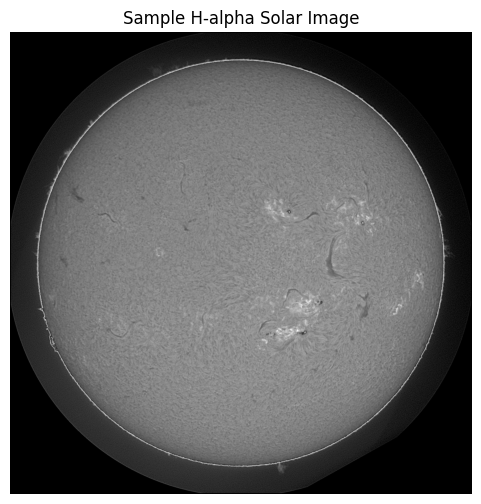

In [19]:
sample_img_name = annotations["images"][0]["file_name"]
sample_img_path = os.path.join(TRAIN_IMG_DIR, sample_img_name)

img_array = cv2.imread(sample_img_path, cv2.IMREAD_GRAYSCALE)

print("Image name:", sample_img_name)
print("Image shape:", img_array.shape)
print("Pixel range:", img_array.min(), img_array.max())

plt.figure(figsize=(6, 6))
plt.imshow(img_array, cmap="gray")
plt.title("Sample H-alpha Solar Image")
plt.axis("off")
plt.show()

In [9]:
%whos

Variable          Type             Data/Info
--------------------------------------------
ANN_PATH          str              ../data/raw/MAGFiLO_1.0_K<...>ons_kaggle2026_train.json
DATA_DIR          str              ../data/raw/MAGFiLO_1.0_Kaggle_2026
TRAIN_IMG_DIR     str              ../data/raw/MAGFiLO_1.0_K<...>e_2026\train\train_images
annotations       dict             n=5
cv2               module           <module 'cv2' from 'c:\\P<...>kages\\cv2\\__init__.py'>
f                 TextIOWrapper    <_io.TextIOWrapper name='<...>de='r' encoding='cp1252'>
img               ndarray          2048x2048: 4194304 elems, type `uint8`, 4194304 bytes (4.0 Mb)
json              module           <module 'json' from 'c:\\<...>\Lib\\json\\__init__.py'>
os                module           <module 'os' (frozen)>
plt               module           <module 'matplotlib.pyplo<...>\\matplotlib\\pyplot.py'>
sample_img_name   str              20140609195854Bh.jpeg
sample_img_path   str              ../dat

In [20]:
# Dataset structure analysis

image_entries = annotations["images"]
annotation_entries = annotations["annotations"]

total_image_entries = len(image_entries)
unique_filenames = len(set(img["file_name"] for img in image_entries))
total_annotations = len(annotation_entries)

filename_counts = {}

for img in image_entries:
    filename = img["file_name"]
    filename_counts[filename] = filename_counts.get(filename, 0) + 1

duplicate_filenames = {
    filename: count
    for filename, count in filename_counts.items()
    if count > 1
}

print("Total annotated image entries :", total_image_entries)
print("Unique image files            :", unique_filenames)
print("Duplicate filenames           :", len(duplicate_filenames))
print("Total filament annotations    :", total_annotations)

Total annotated image entries : 1154
Unique image files            : 707
Duplicate filenames           : 296
Total filament annotations    : 8199


### Dataset Structure Observation

The annotation file contains 1154 annotated image entries corresponding to
707 unique image files. This difference occurs because some image filenames
appear in multiple annotation entries with different image IDs.

Therefore, `image_id` is used as the annotation-level identifier, while
`file_name` identifies the underlying image file.

The dataset contains a total of 8199 annotated filament instances.

In [22]:
# Filament count per annotated image entry

from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

filaments_per_image = Counter(
    ann["image_id"] for ann in annotation_entries
)

filament_counts = list(filaments_per_image.values())

print("Number of annotated image entries:", len(filament_counts))
print("Minimum filaments per image entry:", min(filament_counts))
print("Maximum filaments per image entry:", max(filament_counts))
print("Mean filaments per image entry:", np.mean(filament_counts))
print("Median filaments per image entry:", np.median(filament_counts))

Number of annotated image entries: 1154
Minimum filaments per image entry: 1
Maximum filaments per image entry: 26
Mean filaments per image entry: 7.104852686308492
Median filaments per image entry: 7.0


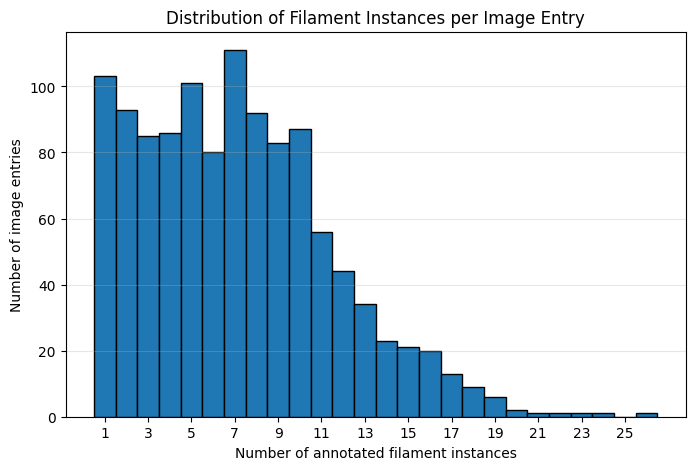

In [23]:
plt.figure(figsize=(8, 5))

plt.hist(
    filament_counts,
    bins=range(1, max(filament_counts) + 2),
    edgecolor="black",
    align="left"
)

plt.xlabel("Number of annotated filament instances")
plt.ylabel("Number of image entries")
plt.title("Distribution of Filament Instances per Image Entry")

plt.xticks(range(1, max(filament_counts) + 1, 2))
plt.grid(axis="y", alpha=0.3)

plt.show()

### Observation

The number of annotated filament instances varies across the dataset, ranging from 1 to 26 per annotated image entry.

The mean number of filament instances is approximately 7.1, while the median is 7.

This variation indicates that the dataset contains images with both sparse and relatively crowded filament structures, which should be considered when designing and evaluating the segmentation approach.

In [24]:
# Filament area distribution

areas = [
    ann["area"]
    for ann in annotation_entries
    if "area" in ann
]

print("Number of annotations with area:", len(areas))
print("Minimum filament area:", min(areas), "pixels")
print("Maximum filament area:", max(areas), "pixels")
print("Mean filament area:", np.mean(areas), "pixels")
print("Median filament area:", np.median(areas), "pixels")
print("75th percentile:", np.percentile(areas, 75), "pixels")
print("95th percentile:", np.percentile(areas, 95), "pixels")

Number of annotations with area: 8199
Minimum filament area: 9.0 pixels
Maximum filament area: 37739.0 pixels
Mean filament area: 2119.8349798755944 pixels
Median filament area: 1228.0 pixels
75th percentile: 2438.0 pixels
95th percentile: 6946.79999999999 pixels


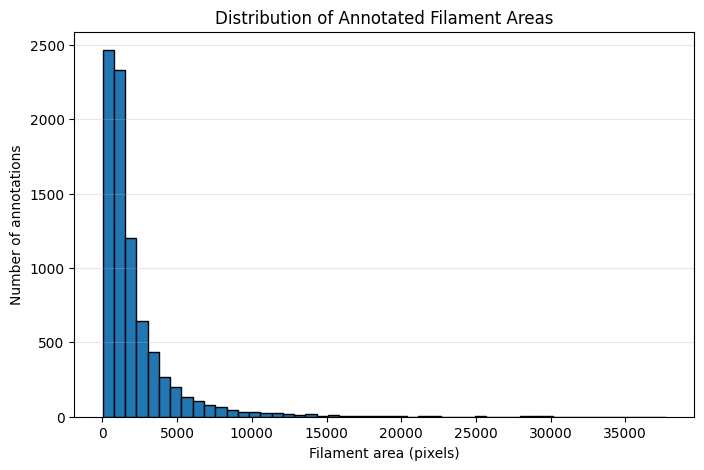

In [25]:
# Distribution of filament areas

plt.figure(figsize=(8, 5))

plt.hist(
    areas,
    bins=50,
    edgecolor="black"
)

plt.xlabel("Filament area (pixels)")
plt.ylabel("Number of annotations")
plt.title("Distribution of Annotated Filament Areas")

plt.grid(axis="y", alpha=0.3)
plt.show()

### Observation

The filament area distribution is strongly right-skewed.

Most annotated filaments occupy relatively small regions, while a smaller number of filaments have substantially larger areas.

The annotated filament areas range from 9 to 37,739 pixels, with a median area of 1,228 pixels.

This indicates substantial variation in filament size within the dataset, which is an important consideration for the segmentation model.

In [26]:
# Filament category distribution

category_counts = Counter(
    ann["category_id"] for ann in annotation_entries
)

category_names = {
    1: "Left",
    2: "Right",
    3: "Unidentifiable",
    4: "Ambiguous"
}

print("Filament category distribution")
print("--------------------------------")

for category_id, count in sorted(category_counts.items()):
    print(
        category_names.get(category_id, f"Unknown ({category_id})"),
        ":",
        count
    )

Filament category distribution
--------------------------------
Left : 2535
Right : 2590
Unidentifiable : 3074


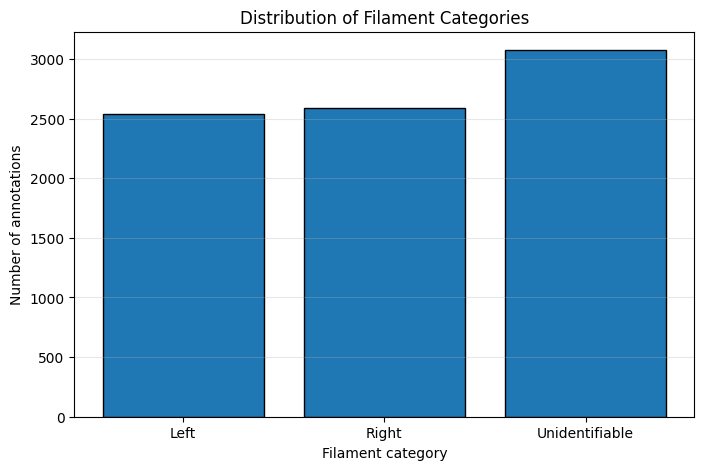

In [27]:
# Category distribution plot

labels = [
    category_names[category_id]
    for category_id in sorted(category_counts)
]

counts = [
    category_counts[category_id]
    for category_id in sorted(category_counts)
]

plt.figure(figsize=(8, 5))

plt.bar(labels, counts, edgecolor="black")

plt.xlabel("Filament category")
plt.ylabel("Number of annotations")
plt.title("Distribution of Filament Categories")

plt.grid(axis="y", alpha=0.3)

plt.show()

### Observation

The training annotations contain three represented filament categories: Left, Right, and Unidentifiable.

Unidentifiable filaments have the highest number of annotations (3,074), followed by Right (2,590) and Left (2,535).

No annotations are assigned to the Ambiguous category in the training annotation file.

The distribution shows that the dataset contains multiple filament categories, which should be considered when defining the segmentation and classification strategy.

In [28]:
# Bounding box dimension analysis

bbox_widths = [
    ann["bbox"][2]
    for ann in annotation_entries
    if "bbox" in ann
]

bbox_heights = [
    ann["bbox"][3]
    for ann in annotation_entries
    if "bbox" in ann
]

print("Number of annotations:", len(bbox_widths))

print("\nBounding box width:")
print("Minimum:", np.min(bbox_widths), "pixels")
print("Maximum:", np.max(bbox_widths), "pixels")
print("Mean:", np.mean(bbox_widths), "pixels")
print("Median:", np.median(bbox_widths), "pixels")

print("\nBounding box height:")
print("Minimum:", np.min(bbox_heights), "pixels")
print("Maximum:", np.max(bbox_heights), "pixels")
print("Mean:", np.mean(bbox_heights), "pixels")
print("Median:", np.median(bbox_heights), "pixels")

Number of annotations: 8199

Bounding box width:
Minimum: 3.819999999999993 pixels
Maximum: 1067.3136 pixels
Mean: 103.2195853762654 pixels
Median: 74.52260000000001 pixels

Bounding box height:
Minimum: 3.4665999999999713 pixels
Maximum: 709.8073999999999 pixels
Mean: 91.78958944993292 pixels
Median: 69.60519999999997 pixels


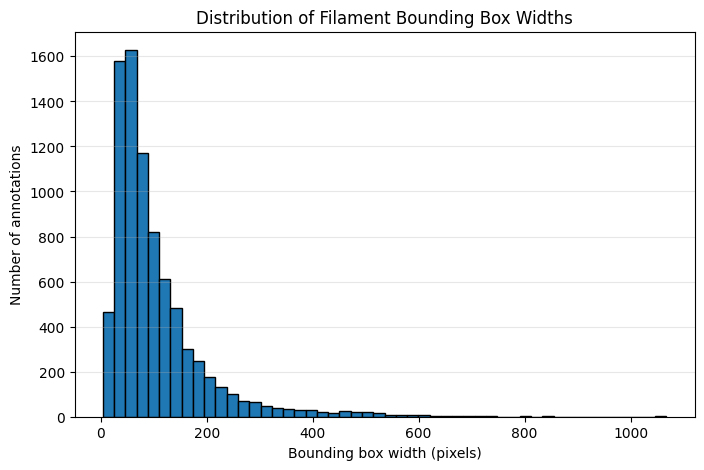

In [29]:
# Bounding box dimension distributions

plt.figure(figsize=(8, 5))

plt.hist(
    bbox_widths,
    bins=50,
    edgecolor="black"
)

plt.xlabel("Bounding box width (pixels)")
plt.ylabel("Number of annotations")
plt.title("Distribution of Filament Bounding Box Widths")

plt.grid(axis="y", alpha=0.3)
plt.show()

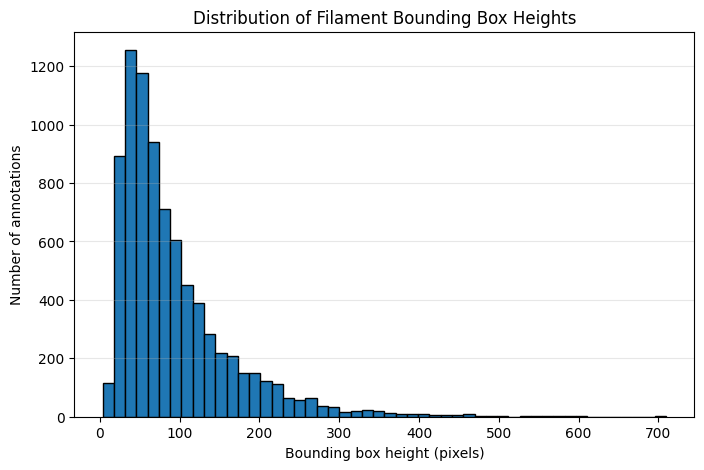

In [30]:
# Distribution of filament bounding box heights

plt.figure(figsize=(8, 5))

plt.hist(
    bbox_heights,
    bins=50,
    edgecolor="black"
)

plt.xlabel("Bounding box height (pixels)")
plt.ylabel("Number of annotations")
plt.title("Distribution of Filament Bounding Box Heights")

plt.grid(axis="y", alpha=0.3)
plt.show()

### Observation

The bounding-box dimensions show substantial variation in the spatial extent of filament instances.

The median bounding-box width is approximately 74.5 pixels, while the median height is approximately 69.6 pixels.

Both width and height distributions are strongly right-skewed, with most filament instances occupying relatively small bounding boxes and a smaller number extending to much larger dimensions.

This variation in spatial scale is an important consideration for the segmentation model, particularly for detecting small filament structures while preserving larger structures.

In [31]:
# Filament spine length analysis

spine_lengths = []

for ann in annotation_entries:
    spine = ann.get("spine", [])

    if len(spine) >= 4:
        # Convert [x1, y1, x2, y2, ...] into coordinate pairs
        points = np.array(spine).reshape(-1, 2)

        # Distance between consecutive spine points
        segment_lengths = np.sqrt(
            np.sum(np.diff(points, axis=0) ** 2, axis=1)
        )

        total_length = np.sum(segment_lengths)
        spine_lengths.append(total_length)

print("Number of annotations with valid spines:", len(spine_lengths))
print("Minimum spine length:", np.min(spine_lengths), "pixels")
print("Maximum spine length:", np.max(spine_lengths), "pixels")
print("Mean spine length:", np.mean(spine_lengths), "pixels")
print("Median spine length:", np.median(spine_lengths), "pixels")

Number of annotations with valid spines: 8199
Minimum spine length: 12.069431689188983 pixels
Maximum spine length: 1104.9543784960867 pixels
Mean spine length: 147.43087404005186 pixels
Median spine length: 111.26782363877267 pixels


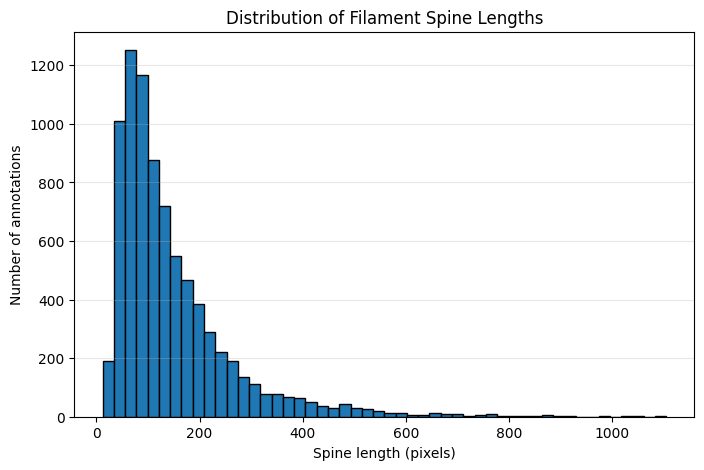

In [32]:
# Distribution of filament spine lengths

plt.figure(figsize=(8, 5))

plt.hist(
    spine_lengths,
    bins=50,
    edgecolor="black"
)

plt.xlabel("Spine length (pixels)")
plt.ylabel("Number of annotations")
plt.title("Distribution of Filament Spine Lengths")

plt.grid(axis="y", alpha=0.3)
plt.show()

### Observation

All 8,199 annotated filament instances contain valid spine information.

The spine lengths range from approximately 12.1 to 1,104.9 pixels, with a median length of approximately 111.3 pixels.

The distribution is strongly right-skewed, indicating that most filament instances have relatively short spines, while a smaller number have substantially longer structures.

The availability of spine annotations provides useful structural information that can be explored in later stages for filament geometry analysis and instance separation.

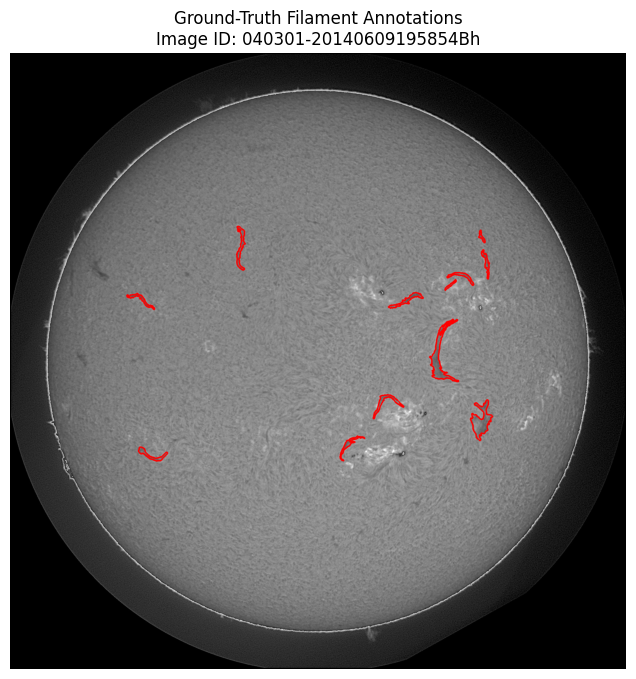

Image ID: 040301-20140609195854Bh
Number of annotated filaments: 12


In [33]:
# Visualize ground-truth filament annotations

sample_image_id = annotations["images"][0]["id"]

sample_annotations = [
    ann
    for ann in annotation_entries
    if ann["image_id"] == sample_image_id
]

overlay = cv2.cvtColor(img_array, cv2.COLOR_GRAY2RGB)

for ann in sample_annotations:
    segmentation = ann.get("segmentation", [])

    for polygon in segmentation:
        points = np.array(polygon, dtype=np.int32).reshape(-1, 2)

        cv2.polylines(
            overlay,
            [points],
            isClosed=True,
            color=(255, 0, 0),
            thickness=3
        )

plt.figure(figsize=(8, 8))
plt.imshow(overlay)
plt.title(
    f"Ground-Truth Filament Annotations\n"
    f"Image ID: {sample_image_id}"
)
plt.axis("off")
plt.show()

print("Image ID:", sample_image_id)
print("Number of annotated filaments:", len(sample_annotations))

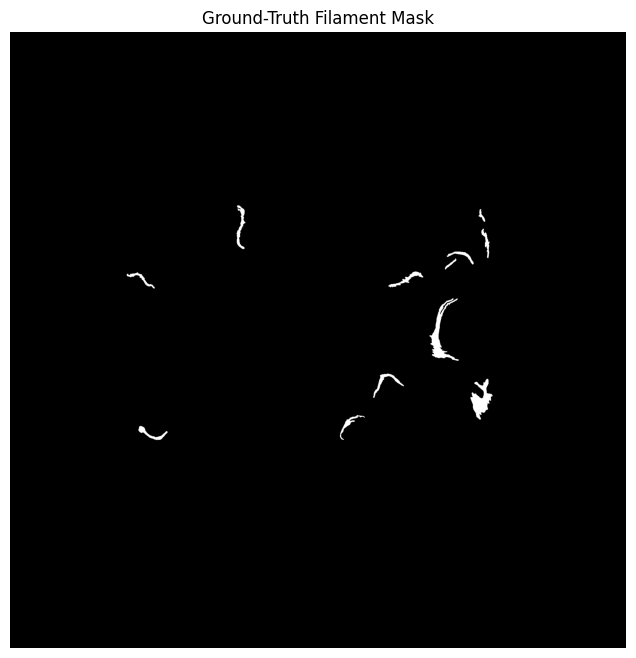

Ground-truth filament pixels: 18663


In [34]:
# Create filled ground-truth mask

gt_mask = np.zeros(img_array.shape, dtype=np.uint8)

for ann in sample_annotations:
    segmentation = ann.get("segmentation", [])

    for polygon in segmentation:
        points = np.array(
            polygon,
            dtype=np.int32
        ).reshape(-1, 2)

        cv2.fillPoly(
            gt_mask,
            [points],
            1
        )

plt.figure(figsize=(8, 8))
plt.imshow(gt_mask, cmap="gray")
plt.title("Ground-Truth Filament Mask")
plt.axis("off")
plt.show()

print("Ground-truth filament pixels:", np.sum(gt_mask))

### Observation

The polygon annotations can be converted into binary segmentation masks, where filament pixels are represented as foreground and the remaining pixels as background.

The ground-truth mask shows that the target structures are thin, elongated and spatially sparse relative to the full 2048 × 2048 solar image.

This representation provides the ground truth required for training and quantitatively evaluating a filament segmentation model.

In [ ]:
for category in annotations["categories"]:
    print("ID:", category["id"], "| Name:", category["name"])

ID: 1 | Name: Left
ID: 2 | Name: Right
ID: 3 | Name: Unidentifiable
ID: 4 | Name: Ambiguous


In [ ]:
print("Sample image entry:")
print(annotations["images"][0])

print("\nSample annotation entry:")
print(annotations["annotations"][0])

Sample image entry:
{'license': 1, 'file_name': '20140609195854Bh.jpeg', 'url': 'https://gong2.nso.edu/HA/hag/201406/20140609/20140609195854Bh.jpg', 'height': 2048, 'width': 2048, 'date_captured': '2014-06-09 19:58:54', 'id': '040301-20140609195854Bh'}

Sample annotation entry:
{'segmentation': [[480.9382, 850.955, 480.307, 852.0535, 478.2989, 852.451, 476.1202, 851.3087, 471.8813, 845.6188, 469.2107, 844.1978, 460.0, 845.0, 459.0, 844.0, 455.9884, 843.2471, 452.2964, 839.9584, 450.6544, 839.7575, 449.7991, 838.6671, 450.223, 837.6258, 447.5581, 834.6278, 445.4449, 829.1312, 442.9577, 825.6077, 441.8277, 824.4777, 438.6437, 823.5973, 439.0, 821.0, 436.0, 818.0, 435.1557, 815.4672, 433.9753, 817.121, 431.9582, 816.9118, 431.3678, 815.4732, 432.1225, 813.1225, 428.0, 809.0, 426.5642, 809.0, 425.6041, 807.9655, 424.4241, 807.9655, 423.838, 809.0, 421.2093, 807.6935, 417.3793, 808.1037, 414.8921, 809.5546, 410.7452, 813.7726, 408.1003, 813.7726, 407.6903, 812.9902, 404.3743, 813.2522, 402.

In [ ]:
import numpy as np

sample_image_info = annotations["images"][0]
sample_image_id = sample_image_info["id"]
sample_img_name = sample_image_info["file_name"]

sample_img_path = os.path.join(TRAIN_IMG_DIR, sample_img_name)
img = cv2.imread(sample_img_path, cv2.IMREAD_GRAYSCALE)

height, width = img.shape
mask = np.zeros((height, width), dtype=np.uint8)

sample_annotations = [
    ann for ann in annotations["annotations"]
    if ann["image_id"] == sample_image_id
]

print("Image ID:", sample_image_id)
print("Image name:", sample_img_name)
print("Number of filaments in this image:", len(sample_annotations))

for ann in sample_annotations:
    for polygon in ann["segmentation"]:
        points = np.array(polygon, dtype=np.int32).reshape((-1, 2))
        cv2.fillPoly(mask, [points], 255)

print("Mask shape:", mask.shape)
print("Mask pixel values:", np.unique(mask))

Image ID: 040301-20140609195854Bh
Image name: 20140609195854Bh.jpeg
Number of filaments in this image: 12
Mask shape: (2048, 2048)
Mask pixel values: [  0 255]


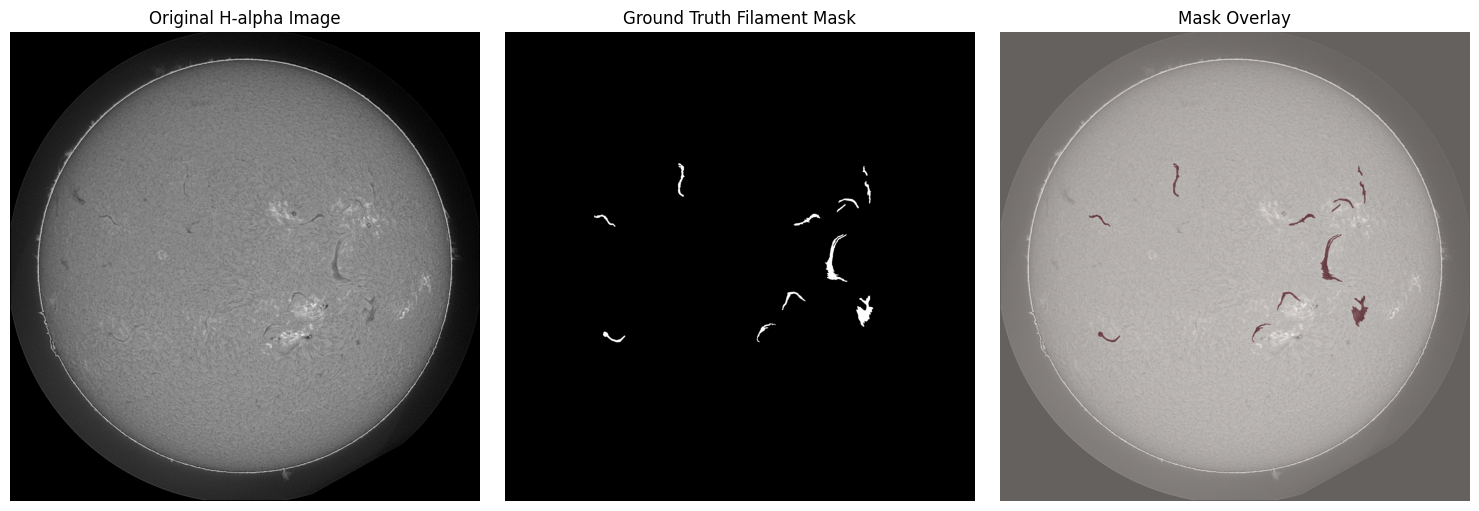

In [ ]:
output_dir = "../results/figures"
os.makedirs(output_dir, exist_ok=True)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original H-alpha Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Filament Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(img, cmap="gray")
plt.imshow(mask, cmap="Reds", alpha=0.4)
plt.title("Mask Overlay")
plt.axis("off")

plt.tight_layout()
plt.savefig("../results/figures/sample_image_mask_overlay.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
from collections import defaultdict
import numpy as np

filaments_per_image = defaultdict(int)

for ann in annotations["annotations"]:
    filaments_per_image[ann["image_id"]] += 1

counts = list(filaments_per_image.values())

print("Number of annotated image entries:", len(counts))
print("Minimum filaments in an image:", np.min(counts))
print("Maximum filaments in an image:", np.max(counts))
print("Average filaments per image:", round(np.mean(counts), 2))
print("Median filaments per image:", np.median(counts))

Number of annotated image entries: 1154
Minimum filaments in an image: 1
Maximum filaments in an image: 26
Average filaments per image: 7.1
Median filaments per image: 7.0


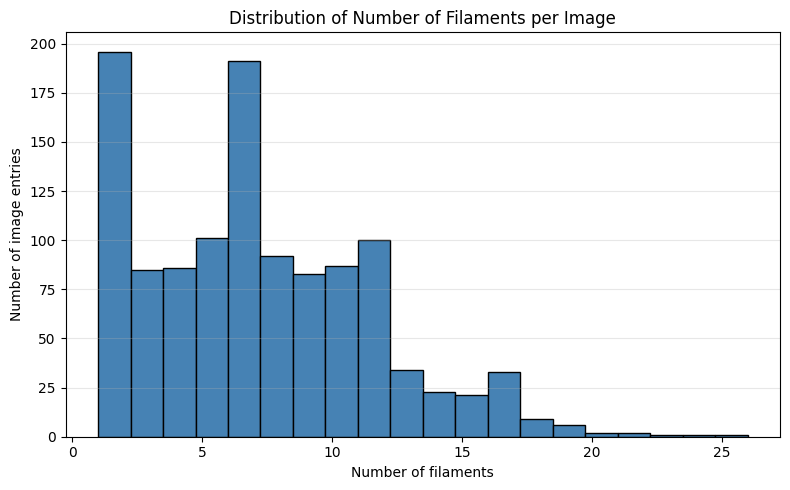

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(counts, bins=20, color="steelblue", edgecolor="black")
plt.title("Distribution of Number of Filaments per Image")
plt.xlabel("Number of filaments")
plt.ylabel("Number of image entries")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("../results/figures/filament_count_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
from collections import Counter

category_id_to_name = {
    category["id"]: category["name"]
    for category in annotations["categories"]
}

category_counts = Counter()

for ann in annotations["annotations"]:
    category_name = category_id_to_name[ann["category_id"]]
    category_counts[category_name] += 1

print("Category distribution:")
for category, count in category_counts.items():
    print(category, ":", count)

Category distribution:
Right : 2590
Unidentifiable : 3074
Left : 2535


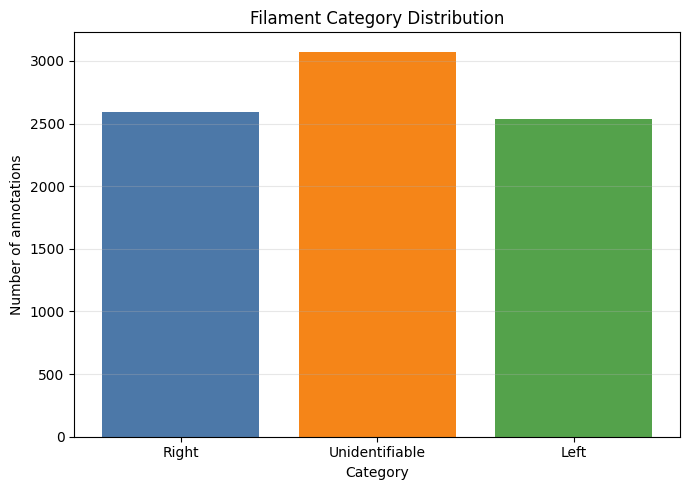

In [ ]:
plt.figure(figsize=(7, 5))
plt.bar(category_counts.keys(), category_counts.values(), color=["#4C78A8", "#F58518", "#54A24B", "#B279A2"])
plt.title("Filament Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of annotations")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("../results/figures/category_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

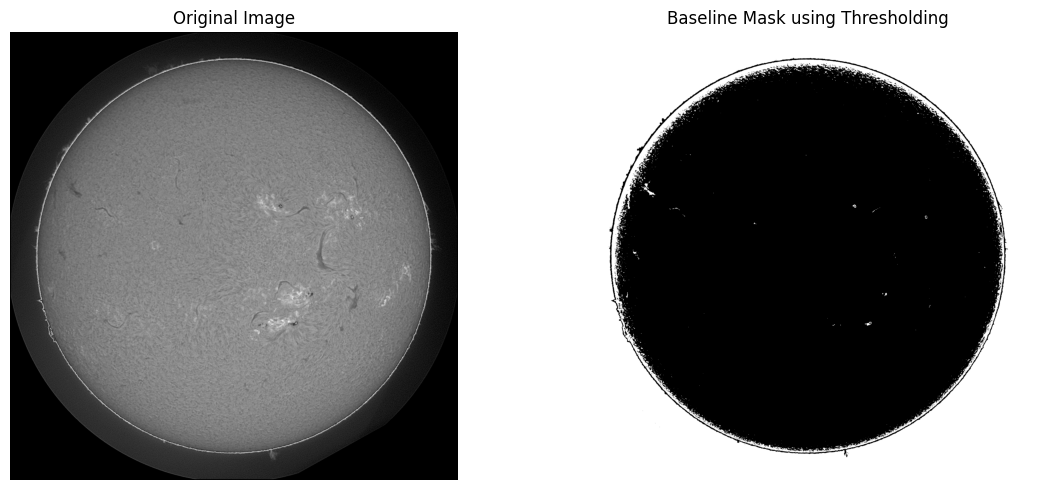

In [ ]:
# Basic thresholding baseline
# Since filaments are usually darker than the surrounding solar surface,
# we try to separate dark regions using a fixed threshold.

threshold_value = 90

_, baseline_mask = cv2.threshold(
    img,
    threshold_value,
    255,
    cv2.THRESH_BINARY_INV
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(baseline_mask, cmap="gray")
plt.title("Baseline Mask using Thresholding")
plt.axis("off")

plt.tight_layout()
plt.show()

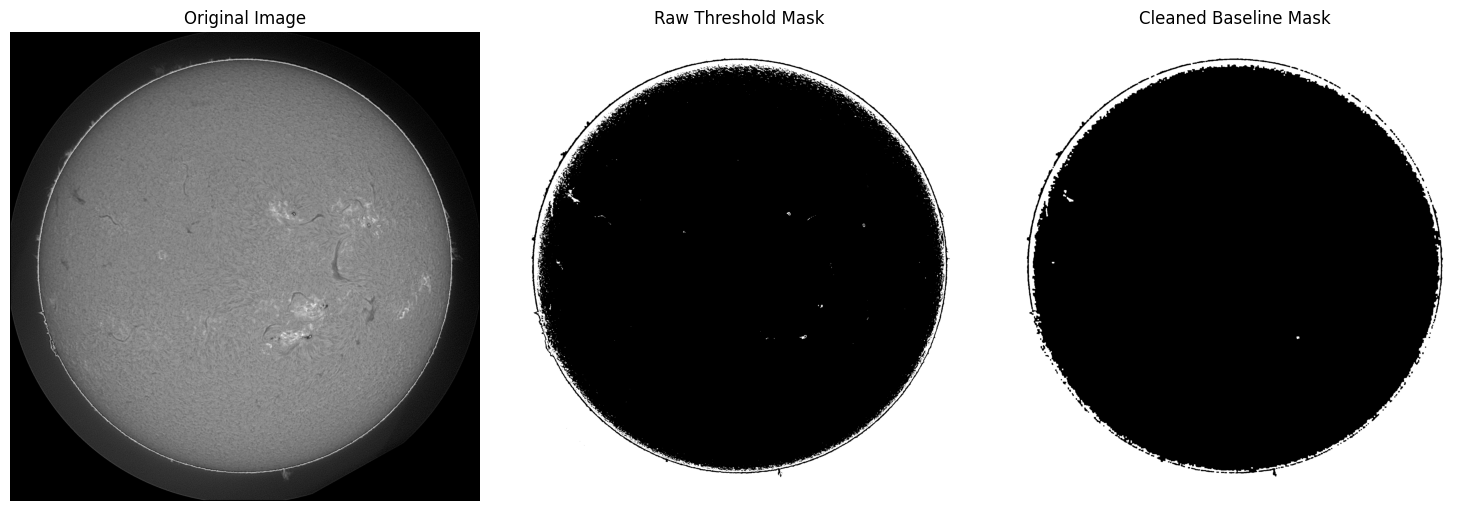

In [ ]:
kernel = np.ones((5, 5), np.uint8)

cleaned_baseline_mask = cv2.morphologyEx(
    baseline_mask,
    cv2.MORPH_OPEN,
    kernel
)

cleaned_baseline_mask = cv2.morphologyEx(
    cleaned_baseline_mask,
    cv2.MORPH_CLOSE,
    kernel
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(baseline_mask, cmap="gray")
plt.title("Raw Threshold Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cleaned_baseline_mask, cmap="gray")
plt.title("Cleaned Baseline Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

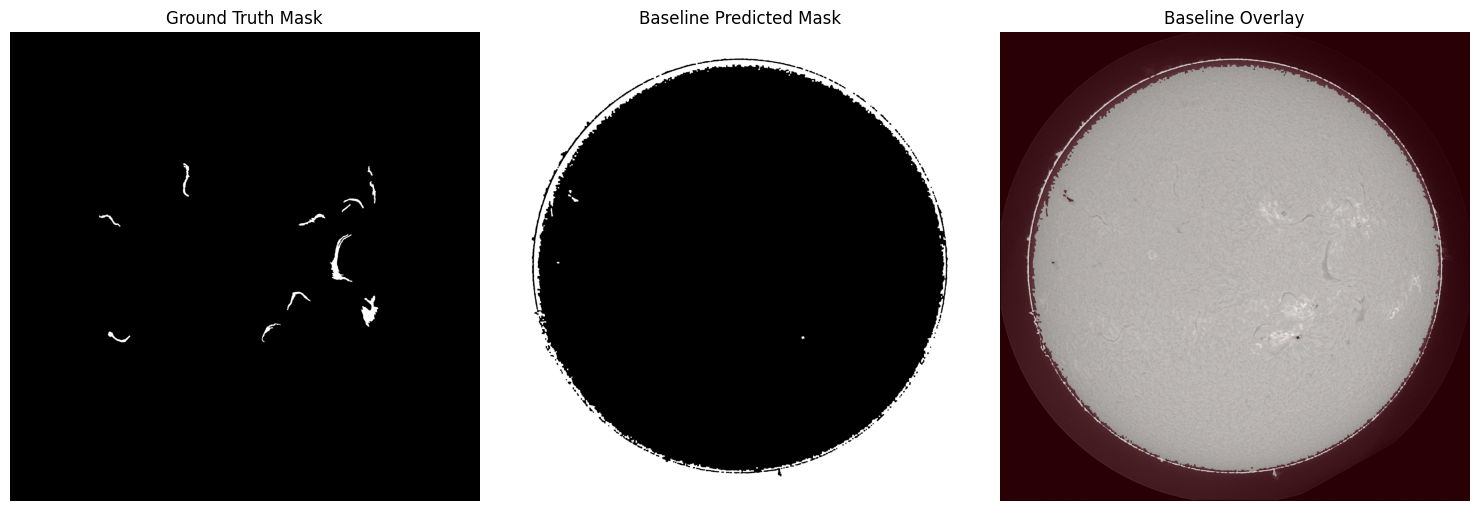

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cleaned_baseline_mask, cmap="gray")
plt.title("Baseline Predicted Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(img, cmap="gray")
plt.imshow(cleaned_baseline_mask, cmap="Reds", alpha=0.4)
plt.title("Baseline Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

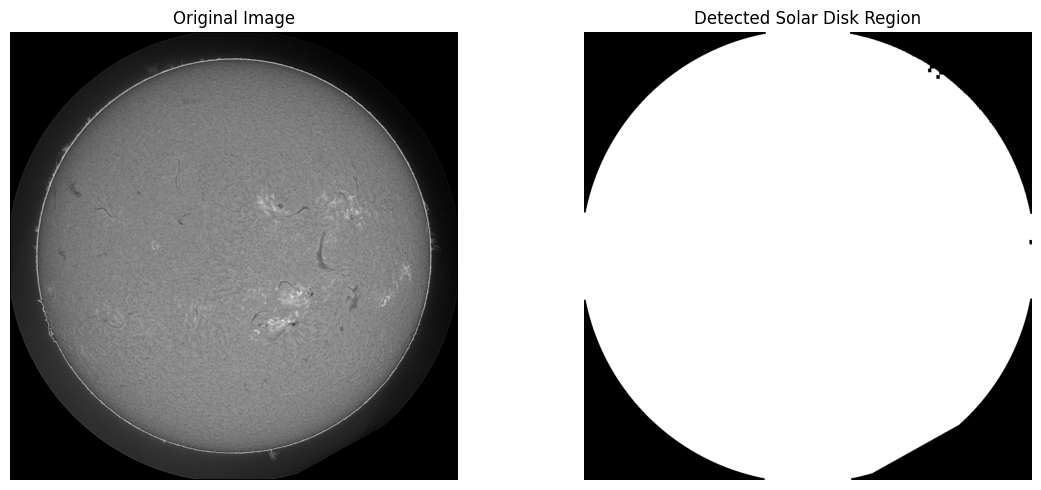

In [ ]:
# Create a mask for the solar disk so that the black outer background is ignored

disk_mask = (img > 20).astype(np.uint8) * 255

kernel = np.ones((15, 15), np.uint8)

disk_mask = cv2.morphologyEx(disk_mask, cv2.MORPH_CLOSE, kernel)
disk_mask = cv2.morphologyEx(disk_mask, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(disk_mask, cmap="gray")
plt.title("Detected Solar Disk Region")
plt.axis("off")

plt.tight_layout()
plt.show()

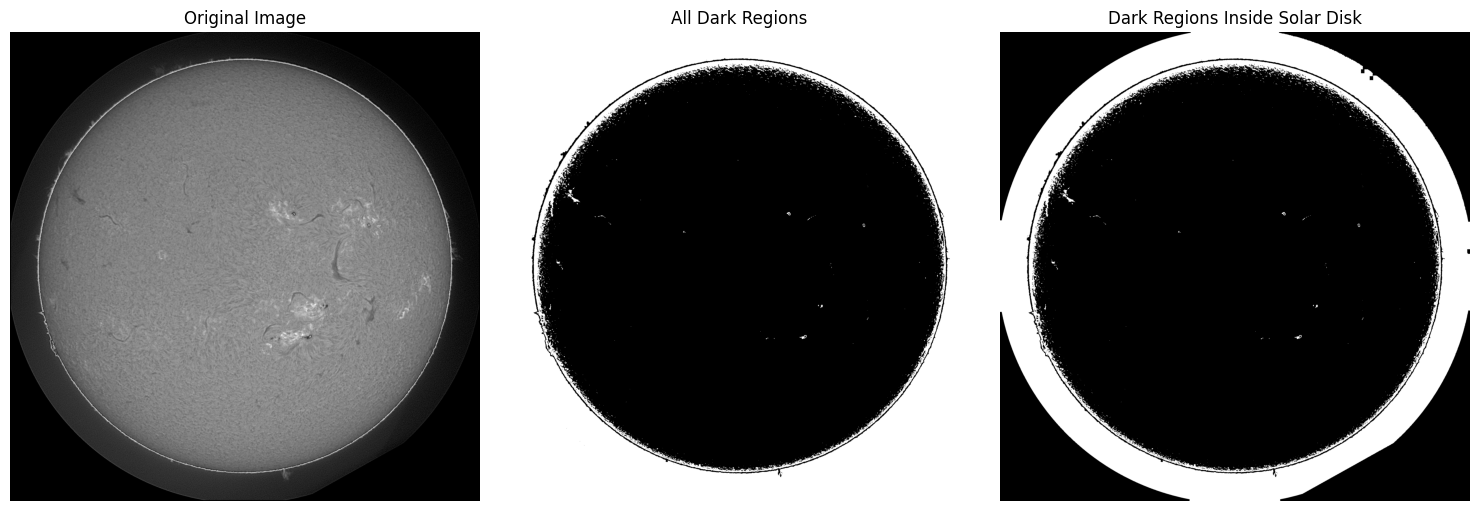

In [ ]:
threshold_value = 90

_, dark_region_mask = cv2.threshold(
    img,
    threshold_value,
    255,
    cv2.THRESH_BINARY_INV
)

baseline_inside_disk = cv2.bitwise_and(dark_region_mask, dark_region_mask, mask=disk_mask)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(dark_region_mask, cmap="gray")
plt.title("All Dark Regions")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(baseline_inside_disk, cmap="gray")
plt.title("Dark Regions Inside Solar Disk")
plt.axis("off")

plt.tight_layout()
plt.show()

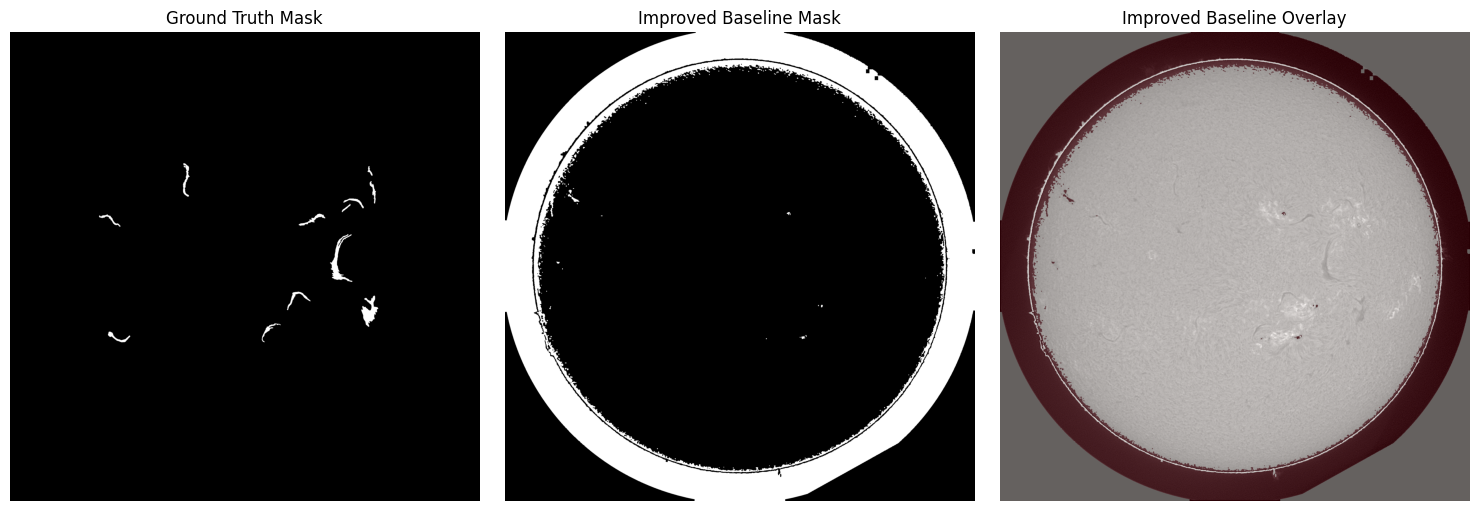

In [ ]:
kernel = np.ones((3, 3), np.uint8)

cleaned_disk_baseline = cv2.morphologyEx(
    baseline_inside_disk,
    cv2.MORPH_OPEN,
    kernel
)

cleaned_disk_baseline = cv2.morphologyEx(
    cleaned_disk_baseline,
    cv2.MORPH_CLOSE,
    kernel
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cleaned_disk_baseline, cmap="gray")
plt.title("Improved Baseline Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(img, cmap="gray")
plt.imshow(cleaned_disk_baseline, cmap="Reds", alpha=0.4)
plt.title("Improved Baseline Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

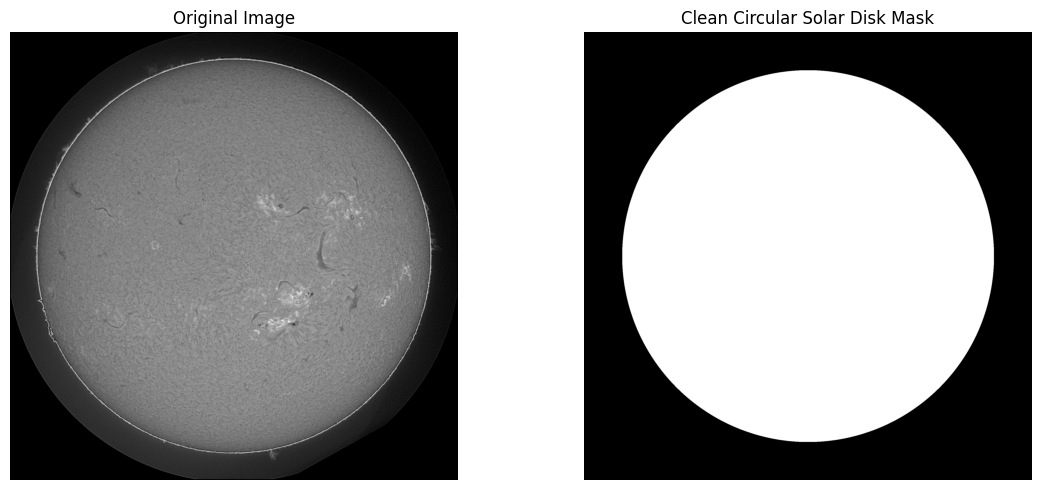

In [ ]:
height, width = img.shape

center_x = width // 2
center_y = height // 2

# Radius chosen slightly smaller than the solar disk to avoid the outer dark/bright border
radius = 850

Y, X = np.ogrid[:height, :width]
distance_from_center = np.sqrt((X - center_x) ** 2 + (Y - center_y) ** 2)

clean_disk_mask = (distance_from_center <= radius).astype(np.uint8) * 255

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(clean_disk_mask, cmap="gray")
plt.title("Clean Circular Solar Disk Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

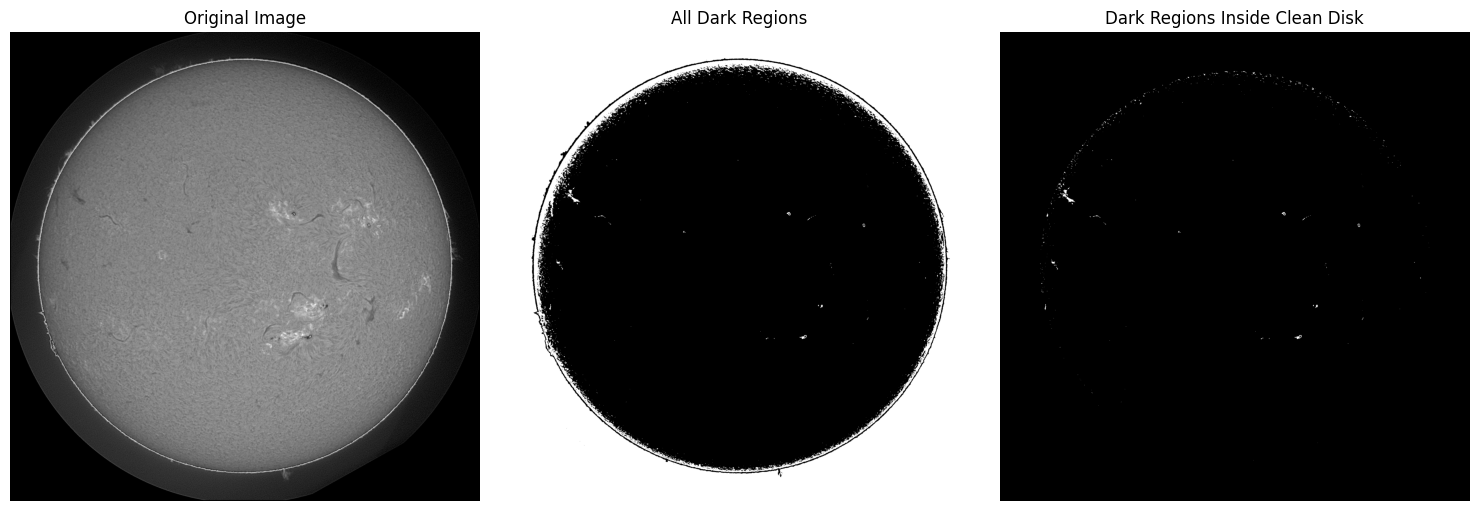

In [ ]:
threshold_value = 90

_, dark_region_mask = cv2.threshold(
    img,
    threshold_value,
    255,
    cv2.THRESH_BINARY_INV
)

clean_baseline_inside_disk = cv2.bitwise_and(
    dark_region_mask,
    dark_region_mask,
    mask=clean_disk_mask
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(dark_region_mask, cmap="gray")
plt.title("All Dark Regions")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(clean_baseline_inside_disk, cmap="gray")
plt.title("Dark Regions Inside Clean Disk")
plt.axis("off")

plt.tight_layout()
plt.show()

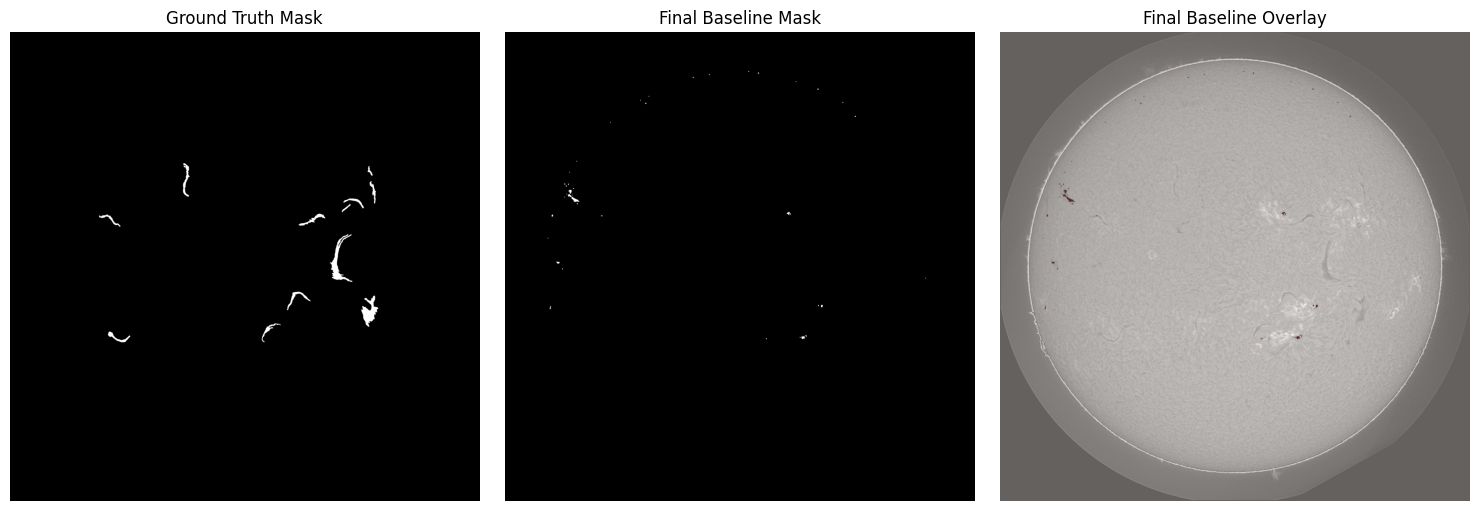

In [ ]:
kernel = np.ones((3, 3), np.uint8)

final_baseline_mask = cv2.morphologyEx(
    clean_baseline_inside_disk,
    cv2.MORPH_OPEN,
    kernel
)

final_baseline_mask = cv2.morphologyEx(
    final_baseline_mask,
    cv2.MORPH_CLOSE,
    kernel
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(final_baseline_mask, cmap="gray")
plt.title("Final Baseline Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(img, cmap="gray")
plt.imshow(final_baseline_mask, cmap="Reds", alpha=0.4)
plt.title("Final Baseline Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

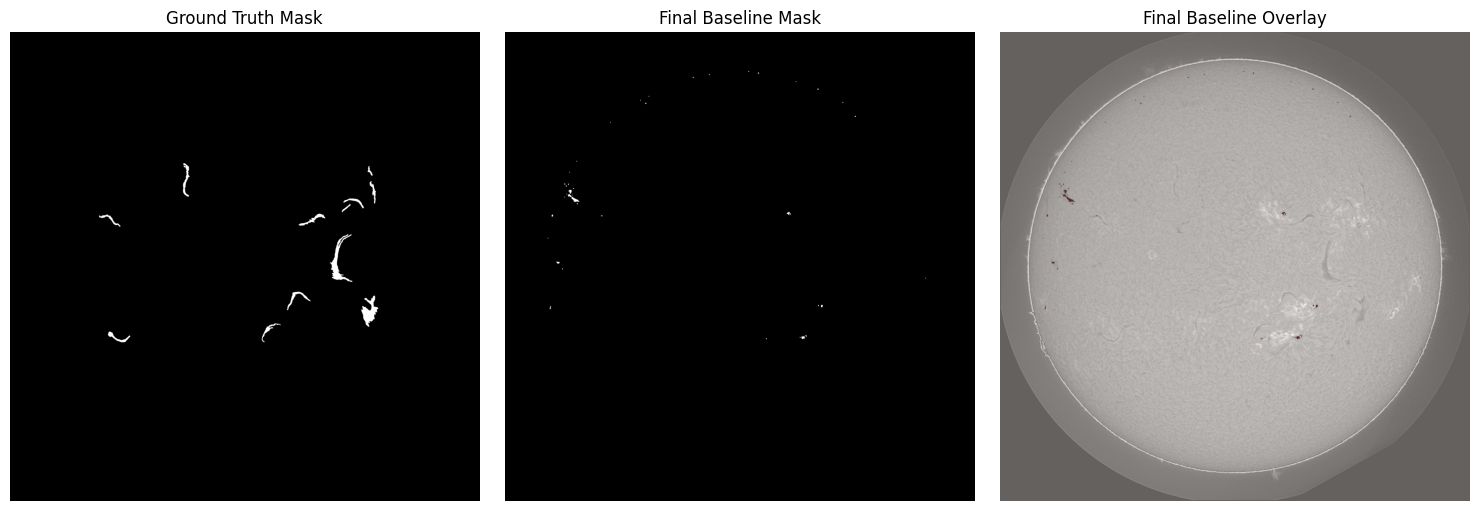

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(final_baseline_mask, cmap="gray")
plt.title("Final Baseline Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(img, cmap="gray")
plt.imshow(final_baseline_mask, cmap="Reds", alpha=0.4)
plt.title("Final Baseline Overlay")
plt.axis("off")

plt.tight_layout()
plt.savefig("../results/figures/final_baseline_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
gt = (mask > 0).astype(np.uint8)
pred = (final_baseline_mask > 0).astype(np.uint8)

intersection = np.logical_and(gt, pred).sum()
union = np.logical_or(gt, pred).sum()

dice = (2 * intersection) / (gt.sum() + pred.sum() + 1e-8)
iou = intersection / (union + 1e-8)

print("Baseline Dice Score:", round(dice, 4))
print("Baseline IoU Score:", round(iou, 4))
print("Ground truth filament pixels:", gt.sum())
print("Predicted filament pixels:", pred.sum())
print("Overlapping pixels:", intersection)

Baseline Dice Score: 0.0021
Baseline IoU Score: 0.001
Ground truth filament pixels: 18663
Predicted filament pixels: 1578
Overlapping pixels: 21


### Baseline Evaluation Observation

A simple thresholding-based baseline was evaluated on 50 annotated image entries.

The baseline achieved a mean Dice score of 0.0340 and a mean IoU score of 0.0178. The corresponding median values were 0.0089 for Dice and 0.0045 for IoU.

The score distributions show that the baseline performs poorly on most evaluated image entries, although a small number of images achieve higher overlap.

These results indicate that fixed intensity thresholding with a solar-disk mask is not sufficient for reliable filament segmentation across the evaluated dataset.

The poor performance motivates the investigation of learning-based segmentation approaches in the next phase of the project.

In [42]:
import pandas as pd

baseline_results = pd.DataFrame({
    "Method": ["Thresholding + Solar Disk Mask"],
    "Dice Score": [round(dice, 4)],
    "IoU Score": [round(iou, 4)],
    "Ground Truth Pixels": [int(gt.sum())],
    "Predicted Pixels": [int(pred.sum())],
    "Overlapping Pixels": [int(intersection)]
})

baseline_results

,Method,Dice Score,IoU Score,Ground Truth Pixels,Predicted Pixels,Overlapping Pixels
0,Thresholding + Solar Disk Mask,0.0,0.0,9165,578,0


In [43]:
baseline_results.to_csv("../results/baseline_outputs/baseline_metrics.csv", index=False)
print("Saved baseline metrics to ../results/baseline_outputs/baseline_metrics.csv")

Saved baseline metrics to ../results/baseline_outputs/baseline_metrics.csv


In [44]:
os.makedirs("../results/baseline_outputs", exist_ok=True)

In [45]:
# Reusable classical baseline function

def create_baseline_mask(img, threshold_value=90, radius=850):
    
    height, width = img.shape

    # Threshold dark regions
    _, dark_region_mask = cv2.threshold(
        img,
        threshold_value,
        255,
        cv2.THRESH_BINARY_INV
    )

    # Create circular solar-disk mask
    center_x = width // 2
    center_y = height // 2

    Y, X = np.ogrid[:height, :width]

    distance_from_center = np.sqrt(
        (X - center_x) ** 2 +
        (Y - center_y) ** 2
    )

    disk_mask = (
        distance_from_center <= radius
    ).astype(np.uint8) * 255

    # Keep dark regions inside solar disk
    baseline_mask = cv2.bitwise_and(
        dark_region_mask,
        dark_region_mask,
        mask=disk_mask
    )

    # Morphological cleaning
    kernel = np.ones((3, 3), np.uint8)

    baseline_mask = cv2.morphologyEx(
        baseline_mask,
        cv2.MORPH_OPEN,
        kernel
    )

    baseline_mask = cv2.morphologyEx(
        baseline_mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    return baseline_mask

In [46]:
# Evaluate baseline on multiple annotated image entries

num_samples = 50

dice_scores = []
iou_scores = []

evaluated_images = 0

for image_info in annotations["images"][:num_samples]:

    image_id = image_info["id"]
    image_name = image_info["file_name"]

    image_path = os.path.join(
        TRAIN_IMG_DIR,
        image_name
    )

    img_eval = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )

    if img_eval is None:
        continue

    # Create ground-truth mask
    gt_mask_eval = np.zeros(
        img_eval.shape,
        dtype=np.uint8
    )

    image_annotations = [
        ann
        for ann in annotation_entries
        if ann["image_id"] == image_id
    ]

    for ann in image_annotations:
        for polygon in ann.get("segmentation", []):

            points = np.array(
                polygon,
                dtype=np.int32
            ).reshape(-1, 2)

            cv2.fillPoly(
                gt_mask_eval,
                [points],
                255
            )

    # Create baseline prediction
    pred_mask_eval = create_baseline_mask(
        img_eval
    )

    # Convert to binary
    gt = gt_mask_eval > 0
    pred = pred_mask_eval > 0

    # Calculate Dice
    intersection = np.logical_and(
        gt,
        pred
    ).sum()

    dice = (
        2 * intersection
        / (gt.sum() + pred.sum() + 1e-8)
    )

    # Calculate IoU
    union = np.logical_or(
        gt,
        pred
    ).sum()

    iou = (
        intersection
        / (union + 1e-8)
    )

    dice_scores.append(dice)
    iou_scores.append(iou)

    evaluated_images += 1


print("Number of image entries evaluated:", evaluated_images)
print("Mean Dice:", round(np.mean(dice_scores), 4))
print("Median Dice:", round(np.median(dice_scores), 4))
print("Mean IoU:", round(np.mean(iou_scores), 4))
print("Median IoU:", round(np.median(iou_scores), 4))

Number of image entries evaluated: 50
Mean Dice: 0.034
Median Dice: 0.0089
Mean IoU: 0.0178
Median IoU: 0.0045


In [47]:
# Multi-image baseline summary
import pandas as pd
baseline_multi_results = pd.DataFrame({
    "Evaluation Set": ["50 annotated image entries"],
    "Mean Dice": [round(np.mean(dice_scores), 4)],
    "Median Dice": [round(np.median(dice_scores), 4)],
    "Mean IoU": [round(np.mean(iou_scores), 4)],
    "Median IoU": [round(np.median(iou_scores), 4)]
})

baseline_multi_results

,Evaluation Set,Mean Dice,Median Dice,Mean IoU,Median IoU
0,50 annotated image entries,0.034,0.0089,0.0178,0.0045


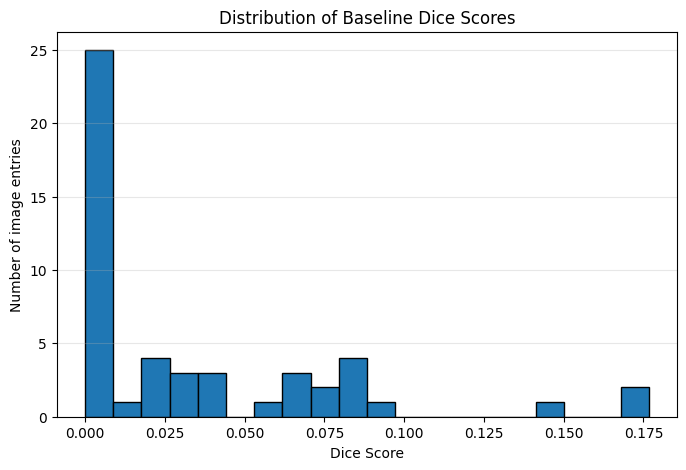

In [48]:
# Distribution of baseline performance

plt.figure(figsize=(8, 5))

plt.hist(
    dice_scores,
    bins=20,
    edgecolor="black"
)

plt.xlabel("Dice Score")
plt.ylabel("Number of image entries")
plt.title("Distribution of Baseline Dice Scores")

plt.grid(axis="y", alpha=0.3)
plt.show()

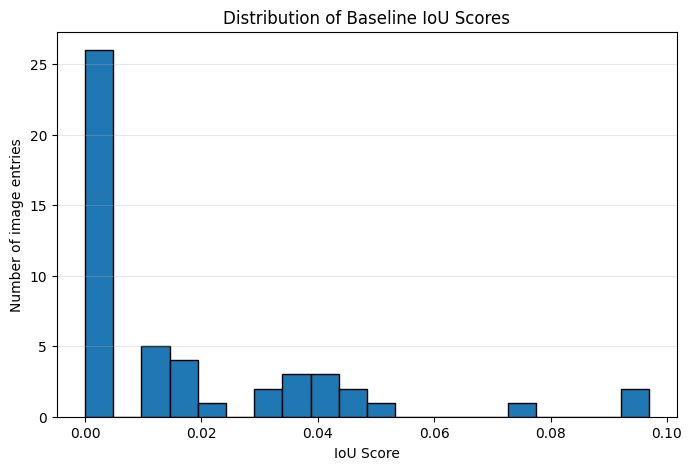

In [49]:
# Distribution of baseline IoU scores

plt.figure(figsize=(8, 5))

plt.hist(
    iou_scores,
    bins=20,
    edgecolor="black"
)

plt.xlabel("IoU Score")
plt.ylabel("Number of image entries")
plt.title("Distribution of Baseline IoU Scores")

plt.grid(axis="y", alpha=0.3)
plt.show()

# Baseline Evaluation — Final Observation

The classical thresholding baseline was evaluated on 50 annotated image entries.

The baseline achieved:

- Mean Dice Score: 0.0340
- Median Dice Score: 0.0089
- Mean IoU: 0.0178
- Median IoU: 0.0045

The Dice and IoU distributions show that most evaluated image entries have low segmentation overlap, while a smaller number of images obtain relatively higher scores.

The results indicate that a fixed intensity threshold combined with a solar-disk mask is not sufficient for reliable filament segmentation across the evaluated dataset.

This experiment provides a quantitative classical baseline against which future deep-learning-based segmentation methods can be compared.

# Proposed Deep-Learning Methodology

The baseline experiment indicates that fixed intensity thresholding is not sufficient for reliable solar filament segmentation across the evaluated images.

Therefore, the next phase of the project will investigate a supervised deep-learning-based segmentation approach.

### Proposed Pipeline

H-alpha Solar Image
↓
Preprocessing
↓
Deep Learning Segmentation Model
↓
Predicted Filament Mask
↓
Post-processing
↓
Segmentation Evaluation

### Initial Model

U-Net will be investigated as the initial deep-learning segmentation architecture because the problem can be formulated as pixel-level binary segmentation.

The input will be an H-alpha solar image, and the target will be the corresponding ground-truth filament mask generated from the provided polygon annotations.

### Planned Data Split

The annotated dataset will be divided into training, validation, and test subsets in the next phase.

- Training set: used for model learning
- Validation set: used for model selection and hyperparameter tuning
- Test set: used for final performance evaluation

### Evaluation Metrics

The deep-learning models will be evaluated using:

- Dice Score
- Intersection over Union (IoU)
- Precision
- Recall

The performance of the learning-based model will also be compared with the classical thresholding baseline established in this phase.

# Presentation 1 — Project Status and Conclusion

## Work Completed

During the first phase of the project, the following tasks were completed:

1. Understood the solar filament segmentation problem.
2. Explored the structure of the provided annotation dataset.
3. Analysed filament instance counts across image entries.
4. Analysed filament area, bounding-box dimensions, and spine lengths.
5. Investigated the distribution of filament annotation categories.
6. Generated ground-truth filament masks from polygon annotations.
7. Visualized annotated filament structures on H-alpha solar images.
8. Developed a classical thresholding-based segmentation baseline.
9. Added solar-disk masking and morphological post-processing.
10. Evaluated the baseline quantitatively on 50 annotated image entries using Dice and IoU.

## Key Findings

The dataset contains diverse filament structures with substantial variation in filament count, size, bounding-box dimensions, and spine length.

The classical baseline produced low segmentation overlap across the evaluated image entries, indicating that fixed intensity thresholding has limitations for this segmentation problem.

## Next Phase

The next phase will focus on supervised deep-learning-based segmentation, beginning with a U-Net-based approach.

The deep-learning model will be trained using the provided ground-truth masks and evaluated using Dice, IoU, Precision, and Recall.

The performance will be compared with the classical baseline established during this phase.

## Current Project Stage

**Phase 1: Dataset Understanding + Exploratory Analysis + Classical Baseline — Completed**